# PyG integration: Exportando dados de Neo4j e treinando GNNs relacionais
## Para esse notebook, temos uma RGCN e uma RGAT

Inicialmente, você precisa instalar as bibliotecas necessárias. Execute o seguinte comando no seu terminal:


In [22]:
# Install necessary dependencies
%pip install graphdatascience torch torch_geometric numpy scikit-learn matplotlib torchinfo pandas coral-pytorch

Note: you may need to restart the kernel to use updated packages.


## Acessando Neo4j

In [23]:
import os
import random
import seaborn as sns

import numpy as np
import torch
import torch.nn.functional as F
from torch_geometric.data import Data
from torch_geometric.nn import RGCNConv,RGATConv

from graphdatascience import GraphDataScience

In [24]:
# Set seeds for consistent results
random.seed(42)
np.random.seed(42)
torch.manual_seed(42)
torch.cuda.manual_seed_all(42)

In [ ]:
# Get Neo4j DB URI, credentials and name from environment if applicable
NEO4J_URI ="bolt://localhost:7687"
NEO4J_AUTH = ("OMITIDO", "OMITIDO")
NEO4J_DB = "neo4j"
gds = GraphDataScience(NEO4J_URI, auth=NEO4J_AUTH, database=NEO4J_DB)

In [26]:
from graphdatascience import ServerVersion

assert gds.server_version() >= ServerVersion(2, 5, 0)

## Download do grafo do Neo4j para o GDS

In [27]:
# Se já houver projeção, apaga e cria novamente
if gds.graph.exists("recommendation_graph"):
    gds.graph.drop("recommendation_graph")

G, result = gds.graph.project.native(
    graph_name="recommendation_graph",
    node_projection={
        "Skill": {
            "properties": ["embedding"]
        },
        "Resume": {},
        "Opportunity": {}
    },
    relationship_projection={
        "BROADER": {},
        "NARROWER": {},
        "ESSENTIAL": {},
        "OPTIONAL": {},
        "HAS_SKILL": {},
        "REQUIRES_SKILL": {}
    }
)

In [28]:
# Exibir informações
print(f"Metadados `G`: {G}")
print(f"Node labels `G`: {G.node_labels()}")
print(f"Relationship types`G`: {G.relationship_types()}")

Metadados `G`: Graph(name=recommendation_graph, node_count=3917, relationship_count=53543)
Node labels `G`: ['Resume', 'Opportunity', 'Skill']
Relationship types`G`: ['HAS_SKILL', 'REQUIRES_SKILL', 'ESSENTIAL', 'NARROWER', 'BROADER', 'OPTIONAL']


## Extraindo matrizes de ajacência e atributos de nós

### 1. Obtenha a topologia do grafo (nó origem, nó destino, tipo de relação)

In [29]:
# Gerando dataframe de topologia
topology_df = gds.graph.relationships.stream(G)
print(topology_df.head())

   sourceNodeId  targetNodeId relationshipType
0             0           951          BROADER
1             0          1402          BROADER
2             1           173          BROADER
3             1          1402          BROADER
4             2           734          BROADER


### 2.Adaptando para transformar em entrada de GNN 

Nessa etapa, estamos ajustando uma estrutura desse formato:
| sourceNodeId  |  targetNodeId  |  relationshipType |
| --- | --- | --- |
| 17 | 42 | HAS_SKILL |
| 17 | 89 | HAS_SKILL |
| 42 | 89 | HAS_SKILL |

Para esse:
```json
{
    "HAS_SKILL": [
        [17, 17, 42],  # source
        [42, 89, 89]   # target
    ]
}
```

In [30]:
topology = topology_df.by_rel_type()

In [31]:
print(f"Relationship type keys: {topology.keys()}")

Relationship type keys: dict_keys(['BROADER', 'ESSENTIAL', 'HAS_SKILL', 'NARROWER', 'OPTIONAL', 'REQUIRES_SKILL'])


In [32]:
# ============================================================
# 1. Criar mapeamento: GDS nodeId -> índice PyTorch
# ============================================================

all_node_ids = sorted(
    set(topology_df["sourceNodeId"]) |
    set(topology_df["targetNodeId"])
)

node_id_to_idx = {
    node_id: idx
    for idx, node_id in enumerate(all_node_ids)
}

num_nodes = len(all_node_ids)

print("Número de nós:", num_nodes)
print("Menor GDS ID:", min(all_node_ids))
print("Maior GDS ID:", max(all_node_ids))


Número de nós: 3917
Menor GDS ID: 0
Maior GDS ID: 4426


## Obtendo matriz de features


### `Skill`: Reaproveitando embeddings de 768 dimensões gerados pelo `embeddinggemma`

In [33]:
skills = gds.graph.node_properties.stream(
    G,
    node_labels=["Skill"],
    node_properties=["embedding"]
)


skills_embeddings = torch.tensor(
    skills["embedding"].to_list()
)

display(skills_embeddings)
embeddings_dimension = len(skills_embeddings[0])
print(f"Tamanho de cada vetor de embeddings da skill: {embeddings_dimension}")

tensor([[-0.0334, -0.0223, -0.0041,  ..., -0.0286,  0.0071, -0.0752],
        [ 0.0164, -0.0297, -0.0162,  ...,  0.0206,  0.0250,  0.0111],
        [-0.0392, -0.0509, -0.0064,  ..., -0.0435, -0.0057, -0.0477],
        ...,
        [-0.0283,  0.0310,  0.0040,  ..., -0.0154,  0.0024, -0.0171],
        [-0.0649, -0.0159, -0.0364,  ...,  0.0016, -0.0029,  0.0514],
        [-0.0107,  0.0290,  0.0138,  ..., -0.0045,  0.0043,  0.0242]])

Tamanho de cada vetor de embeddings da skill: 768


### Visualizando a distribuição das skills em 2D

A projeção PCA mostra as direções de maior variância dos embeddings. Uma nuvem muito concentrada, alongada em uma direção ou distante da origem pode indicar anisotropia. A projeção é apenas uma inspeção visual; ela não substitui métricas no espaço original de 768 dimensões.



=== Embeddings originais das skills ===
Quantidade de vetores: 1924
Norma da direção média: 0.583403
Cosseno médio entre pares: 0.340313
Desvio dos cossenos: 0.095558
Norma média: 1.000000
Coeficiente de variação das normas: 0.000000
Variância na PC1: 8.09%
Variância acumulada nas 10 primeiras PCs: 27.34%
Effective rank: 191.93 de 768
Cosseno médio após centralização: -0.000313
Cosseno médio após whitening: -0.000208


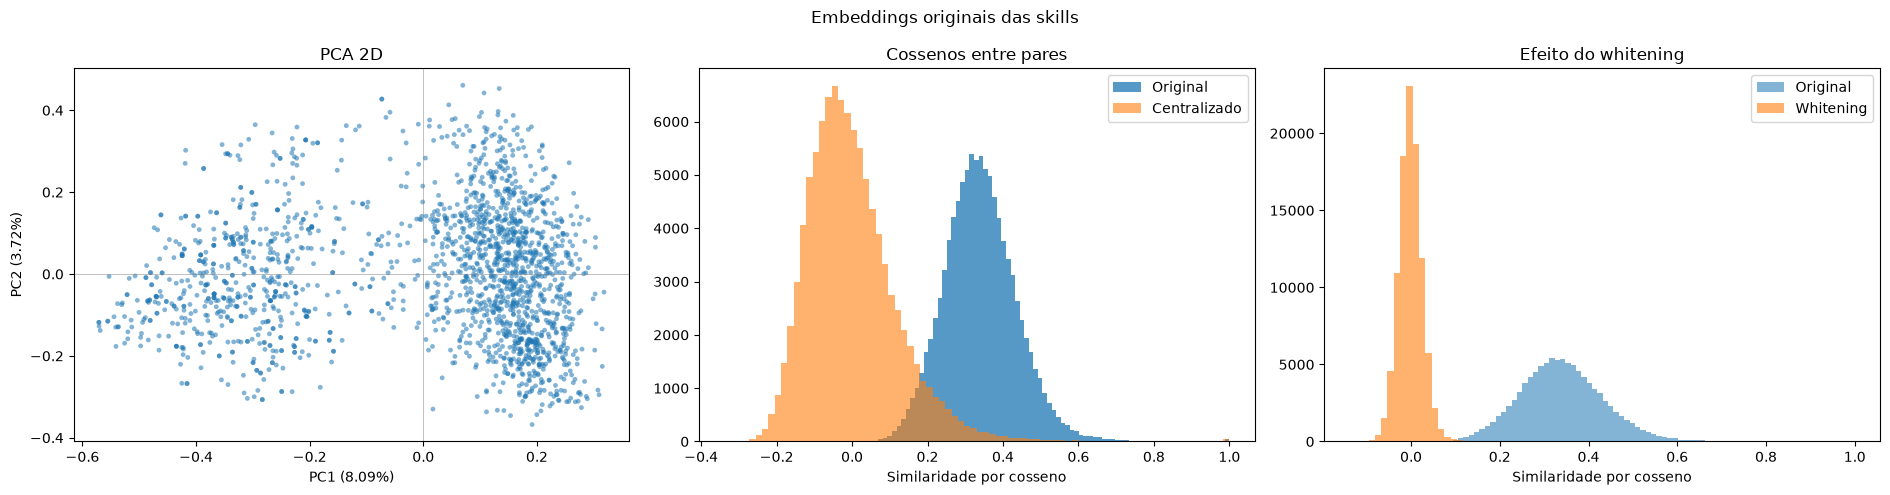

In [34]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

def analyze_embedding_space(embeddings, label, pair_samples=100_000):
    """Calcula métricas e gráficos para investigar anisotropia."""
    vectors = embeddings.detach().float().cpu()
    normalized = F.normalize(vectors, p=2, dim=1)

    # 1. Concentração em uma direção média.
    mean_direction_norm = normalized.mean(dim=0).norm().item()

    # 2. Similaridade entre pares aleatórios, sem construir uma matriz N x N.
    generator = torch.Generator().manual_seed(42)
    sample_size = min(pair_samples, len(normalized) ** 2)
    i = torch.randint(len(normalized), (sample_size,), generator=generator)
    j = torch.randint(len(normalized), (sample_size,), generator=generator)
    pairwise_cosines = (normalized[i] * normalized[j]).sum(dim=1)

    # 3. Distribuição das normas.
    norms = vectors.norm(dim=1)
    norm_cv = (norms.std() / norms.mean().clamp_min(1e-12)).item()

    # 4. Espectro da PCA e effective rank.
    pca_full = PCA().fit(vectors.numpy())
    explained = pca_full.explained_variance_ratio_
    entropy = -(explained * np.log(explained + 1e-12)).sum()
    effective_rank = float(np.exp(entropy))

    # 5. Efeito da centralização e do whitening nas similaridades.
    centered = vectors - vectors.mean(dim=0, keepdim=True)
    centered_normalized = F.normalize(centered, p=2, dim=1)
    centered_cosines = (centered_normalized[i] * centered_normalized[j]).sum(dim=1)

    pca_whitening = PCA(whiten=True).fit_transform(vectors.numpy())
    whitened = torch.from_numpy(pca_whitening).float()
    whitened = F.normalize(whitened, p=2, dim=1)
    whitened_cosines = (whitened[i] * whitened[j]).sum(dim=1)

    print(f"\n=== {label} ===")
    print(f"Quantidade de vetores: {len(vectors)}")
    print(f"Norma da direção média: {mean_direction_norm:.6f}")
    print(f"Cosseno médio entre pares: {pairwise_cosines.mean().item():.6f}")
    print(f"Desvio dos cossenos: {pairwise_cosines.std().item():.6f}")
    print(f"Norma média: {norms.mean().item():.6f}")
    print(f"Coeficiente de variação das normas: {norm_cv:.6f}")
    print(f"Variância na PC1: {explained[0] * 100:.2f}%")
    print(f"Variância acumulada nas 10 primeiras PCs: {explained[:10].sum() * 100:.2f}%")
    print(f"Effective rank: {effective_rank:.2f} de {vectors.shape[1]}")
    print(f"Cosseno médio após centralização: {centered_cosines.mean().item():.6f}")
    print(f"Cosseno médio após whitening: {whitened_cosines.mean().item():.6f}")

    # PCA 2D e histogramas das similaridades.
    pca_2d = PCA(n_components=2)
    vectors_2d = pca_2d.fit_transform(vectors.numpy())
    fig, axes = plt.subplots(1, 3, figsize=(19, 5))
    axes[0].scatter(vectors_2d[:, 0], vectors_2d[:, 1], s=12, alpha=0.55, edgecolors="none")
    axes[0].axhline(0, color="gray", linewidth=0.7, alpha=0.5)
    axes[0].axvline(0, color="gray", linewidth=0.7, alpha=0.5)
    axes[0].set_title("PCA 2D")
    axes[0].set_xlabel(f"PC1 ({pca_2d.explained_variance_ratio_[0] * 100:.2f}%)")
    axes[0].set_ylabel(f"PC2 ({pca_2d.explained_variance_ratio_[1] * 100:.2f}%)")
    axes[1].hist(pairwise_cosines.numpy(), bins=80, alpha=0.75, label="Original")
    axes[1].hist(centered_cosines.numpy(), bins=80, alpha=0.60, label="Centralizado")
    axes[1].set_title("Cossenos entre pares")
    axes[1].set_xlabel("Similaridade por cosseno")
    axes[1].legend()
    axes[2].hist(pairwise_cosines.numpy(), bins=80, alpha=0.55, label="Original")
    axes[2].hist(whitened_cosines.numpy(), bins=80, alpha=0.60, label="Whitening")
    axes[2].set_title("Efeito do whitening")
    axes[2].set_xlabel("Similaridade por cosseno")
    axes[2].legend()
    fig.suptitle(label)
    plt.tight_layout()
    plt.show()

    return {
        "mean_direction_norm": mean_direction_norm,
        "pairwise_cosine_mean": pairwise_cosines.mean().item(),
        "pairwise_cosine_std": pairwise_cosines.std().item(),
        "norm_cv": norm_cv,
        "explained_variance": explained,
        "effective_rank": effective_rank,
        "centered_cosine_mean": centered_cosines.mean().item(),
        "whitened_cosine_mean": whitened_cosines.mean().item(),
    }

skill_analysis_original = analyze_embedding_space(
    skills_embeddings,
    "Embeddings originais das skills"
)


In [35]:
mean_embedding = skills_embeddings.mean(axis=0)

print(np.linalg.norm(mean_embedding))

0.5834033


In [36]:
mean_norm = np.linalg.norm(skills_embeddings.mean(axis=0))
avg_norm = np.linalg.norm(skills_embeddings, axis=1).mean()

ratio = mean_norm / avg_norm

print("Mean norm:", mean_norm)
print("Average norm:", avg_norm)
print("Ratio:", ratio)

Mean norm: 0.5834033
Average norm: 1.0
Ratio: 0.5834033


### `Opportunity` e `Resume`: Gerando vetor aleatório de mesma dimensão

A ideia é perceber se a GNN consegue aprender a partir de embeddings de skills e vetores como valores iniciais aleatórios de oportunidades e currículos 

In [37]:
# ============================================================
# 2. Inicializar X
# ============================================================
num_nodes = G.node_count()

x = torch.randn(num_nodes, embeddings_dimension)
print(x.shape)

torch.Size([3917, 768])


In [39]:
# ============================================================
# 3. Substituir embeddings aleatórios das Skills
#    pelos embeddings semânticos reais
# ============================================================

for _, row in skills.iterrows():

    gds_node_id = int(row["nodeId"])

    pytorch_idx = node_id_to_idx[gds_node_id]

    x[pytorch_idx] = torch.tensor(
        row["embedding"],
        dtype=torch.float32
    )




In [40]:

# ============================================================
# 4. Remapear a topologia para índices consecutivos
# ============================================================

topology_normalized = topology_df.copy()

topology_normalized["sourceNodeId"] = (
    topology_normalized["sourceNodeId"]
    .map(node_id_to_idx)
)

topology_normalized["targetNodeId"] = (
    topology_normalized["targetNodeId"]
    .map(node_id_to_idx)
)

## Obtendo matriz de relações

### 1. Ajustando a direção do envio de mensagens na GNN

Como queremos construir embeddings para currículos e oportunidades que agreguem informações dos nós que representam suas características, como nós `Skill`, conectados a partir de  `HAS_SKILL` e `REQUIRES_SKILL`.

Sendo assim, entendemos que as informações devem terminar em currículos e oportunidades, e não sair delas. Ao mesmo tempo, as informações podem fluir entre habilidades, para que seus embeddings, inicialmente obtidos do `embeddinggemma`, sejam evoluídos a partir da ontologia ESCO.

Para isso, reverteremos `HAS_SKILL` e `REQUIRES_SKILL`: 

ex:
```json
{
    "HAS_SKILL": [
        [17, 17, 42],  # source
        [42, 89, 89]   # target
    ]
}
```

Queremos transformar em `tensor`:
```json
{
    "HAS_SKILL": tensor([
        [17, 17, 42],  # source
        [42, 89, 89]   # target
    ])
}
```

E reverter as arestas:
```json
{
    "HAS_SKILL_REV": tensor([
        [42, 89, 89], #source
        [17, 17, 42]  #target
    ])
}
```

Por outro lado, sobre as `Skill`, por serem relações da ontologia, vamos manter como estão


In [41]:
# ============================================================
# 5. Criar edge_index_dict
# ============================================================

relation_names = topology_normalized[
    "relationshipType"
].unique().tolist()

edge_index_dict = {}

for relation in relation_names:

    relation_df = topology_normalized[
        topology_normalized["relationshipType"] == relation
    ]

    edge_index = torch.tensor(
        [
            relation_df["sourceNodeId"].tolist(),
            relation_df["targetNodeId"].tolist()
        ],
        dtype=torch.long
    )

    edge_index_dict[relation] = edge_index


# ============================================================
# 6. Criar relações reversas
# ============================================================

# Relações entre Skill serão mantidas
esco_relations = {
    "BROADER",
    "NARROWER",
    "ESSENTIAL",
    "OPTIONAL"
}

original_relations = list(edge_index_dict.keys())

for relation in original_relations:

    if relation not in esco_relations:

        #Criando relação reversa
        edge_index_dict[relation + "_REV"] = (
            edge_index_dict[relation].flip(0)
        )

        #Removendo original
        edge_index_dict.pop(relation,None)

# ============================================================
# 7. Criar dicionário de IDs das relações
# ============================================================

relations = {
    relation: relation_id
    for relation_id, relation
    in enumerate(edge_index_dict.keys())
}

print("Relações mantidas:")
for relation,relation_id in relations.items():
    print(f"{relation}:{relation_id}" )



Relações mantidas:
BROADER:0
OPTIONAL:1
NARROWER:2
ESSENTIAL:3
REQUIRES_SKILL_REV:4
HAS_SKILL_REV:5


### 2. Obter vetores `edge_index` e `edge_type`

Queremos obter um vetor `edge_index` que represente os índices dos nós associados do grafo, e um vetor `edge_type` que para cada posição, possui um índice do tipo

Ex: Considerando o exemplo da `HAS_SKILL` e `HAS_SKILL_REV` das células anteriores

```python
edge_index = tensor([
        [17, 17, 42, 42, 89, 89],  # source
        [42, 89, 89, 17, 17, 42]   # target
    ])
```

Agora, para a GNN saber qual é a relação original do grafo e qual foi a relação criada artificialmente, precisamos criar um vetor `edge_type` com índices diferentes para a relação normal e a inversa

Sendo `HAS_SKILL` = 0 e `HAS_SKILL_REV`(invertida) = 1
```python
edge_type = tensor([
    0,0,0,1,1,1
])

In [42]:
# ============================================================
# 8. Construir edge_index e edge_type
# ============================================================

edge_indices = []
edge_types = []

for relation, relation_id in relations.items():

    edges = edge_index_dict[relation]

    edge_indices.append(edges)

    edge_types.append(
        torch.full(
            (edges.size(1),),
            relation_id,
            dtype=torch.long
        )
    )


edge_index = torch.cat(
    edge_indices,
    dim=1
)

edge_type = torch.cat(
    edge_types,
    dim=0
)

## 3. Dados de entrada prontos

Agora temos:
* `x`:  matriz de features com nós `RESUME`,`OPPORTUNITY`, `SKILL`, onde `RESUME`,`OPPORTUNITY` possuem vetores iniciais aleatórios, enquanto `SKILL` já possui valor semântico obtido com `embeddinggemma`. Os vetores das três classes possui 768 dimensões
* `y` = `None`: Sendo uma tarefa de predição de links e não predição de classes de nós, não temos um conjunto `y` de classes previstas
* `edge_index`: matriz de índices de nós nas relações
* `edge_type`: lista com tipos das relações de `edge_index`

In [43]:
# ============================================================
# 9. Criar Data do PyG
# ============================================================

data = Data(
    x=x,
    edge_index=edge_index,
    edge_type=edge_type
)


# ============================================================
# 10. Verificações
# ============================================================

print(data)

print("Número de nós:", data.x.size(0))
print("Número de arestas:", data.edge_index.size(1))
print("Maior índice:", data.edge_index.max().item())
print("Menor índice:", data.edge_index.min().item())
print("Número de relações:", len(relations))

Data(x=[3917, 768], edge_index=[2, 53543], edge_type=[53543])
Número de nós: 3917
Número de arestas: 53543
Maior índice: 3916
Menor índice: 0
Número de relações: 6


## Treinando RGCN para gerar embeddings

### 1. Definindo arquitetura da rede

Para testar, vamos supor uma RGCN no formato:
```txt

                   X
             [2524 × 768]
                   │
                   ▼
       ┌──────────────────────────┐
       │   RGCNConv (aggr=soma)   │
       │      768 → 768           │
       └──────────────────────────┘
                   │
                  ReLU
                   │
                   ▼
       ┌──────────────────────────┐
       │   RGCNConv (aggr=soma)   │
       │      768 → 768           │
       └──────────────────────────┘
                   │
                   ▼
          Z(matriz X após GNN) [2524 × 768]
```

In [44]:
# Define the RGCN architecture
class RGCN(torch.nn.Module):
    def __init__(
            self,
            input_dim,
            hidden_dim,
            output_dim,
            num_relations
        ):
        super().__init__()
        self.conv1 = RGCNConv(in_channels=input_dim,
                              out_channels=hidden_dim,
                              num_relations=num_relations,
                              aggr="add")
        self.conv2 = RGCNConv(in_channels=hidden_dim,
                              out_channels=output_dim,
                              num_relations=num_relations,
                              aggr="add")

    def forward(self, x, edge_index, edge_type):
        x = self.conv1(x, edge_index,edge_type)
        x = F.relu(x)
        # x = F.dropout(x, training=self.training)
        x = self.conv2(x, edge_index,edge_type)

        #Retorna a matriz de features agregada
        return x

### 2. Descobrir qual processador está disponível

Nessa etapa, descobre se possui GPU disponível, usando CPU em caso negativo

Além disso, carrega o modelo `RGCN` e os dados de entrada `data` para esse processador

In [45]:
# Prepare training by setting up for the chosen device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Let's see what device was chosen
print(device)

cpu


In [46]:
from torchinfo import summary
# criando modelo e carregando na CPU ou GPU
model = RGCN(
    input_dim=embeddings_dimension,
    hidden_dim=embeddings_dimension,
    output_dim=embeddings_dimension,
    num_relations=len(relations)
    ).to(device)

# Inspecionando arquitetura
print(summary(model))

# Carregando os dados de entrada na CPU ou GPU
data = data.to(device)

Layer (type:depth-idx)                   Param #
RGCN                                     --
├─RGCNConv: 1-1                          4,129,536
│    └─SumAggregation: 2-1               --
├─RGCNConv: 1-2                          4,129,536
│    └─SumAggregation: 2-2               --
Total params: 8,259,072
Trainable params: 8,259,072
Non-trainable params: 0


### 3. Montando dataset de treino

Para treinamento de qualquer rede neural, precisamos de um conjunto com as respostas esperadas para computar a função de perda e ajustar os pesos.

Sendo as avaliações com usuários o nosso ground truth, teremos um dataset no formato:


| `resume_id` | `opportunity_id` | `recommendation_engine`|  `applied` | `adherence_score` |
| --- | --- | --- | --- | --- |
| 123 | 432 | "bm25" | 1 | 4 |
| 345 | 864 | "jaccard" | 0 | 2 |
...

Com isso, podemos usar os embeddings agregados pela RGCN, criar pares currículo/oportunidade e treinar um decoder a partir de uma MLP que irá predizer a probabilidade de um currículo se candidatar a uma oportunidade e de uma OrdinalMLP que irá predizer a aderência do currículo à oportunidade. Essas saídas são utilizadas para o cálculo da perda e o ajuste dos pesos da RGCN.

#### 3.1 Carregando o ground truth do `bn_sintetico.csv`

Cada registro do CSV representa um par currículo/oportunidade e contém os dois alvos supervisionados usados pelo modelo: `applied` e `adherence_score`. O campo `recommendation_engine` é mantido no dataframe para rastreabilidade, mas não entra no decoder: as entradas das duas redes de saída são somente os embeddings concatenados do currículo e da oportunidade.

Os identificadores UUID do CSV são associados aos índices dos nós no grafo por meio da propriedade `id` persistida no Neo4j. Assim, os alvos permanecem alinhados aos embeddings produzidos pela RGCN.

In [47]:
from pathlib import Path
import pandas as pd
from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)

ground_truth_path = next(
    path for path in (
        Path("bn_sintetico.csv"),
        Path("playground/bn_sintetico.csv"),
    )
    if path.exists()
)
ground_truth = pd.read_csv(ground_truth_path)

required_columns = {
    "resume_id",
    "opportunity_id",
    "recommendation_engine",
    "applied",
    "adherence_score",
}
missing_columns = required_columns.difference(ground_truth.columns)
if missing_columns:
    raise ValueError(f"Colunas ausentes no ground truth: {sorted(missing_columns)}")

if not ground_truth[["applied", "adherence_score"]].notna().all().all():
    raise ValueError("O ground truth contém valores ausentes nos alvos.")

if not ground_truth["applied"].isin([0, 1]).all():
    raise ValueError("`applied` deve conter somente 0 ou 1.")

for column in ["adherence_score"]:
    if not ground_truth[column].isin([1, 2, 3, 4, 5]).all():
        raise ValueError(f"`{column}` deve conter inteiros entre 1 e 5.")

resume_nodes = gds.run_cypher("""
MATCH (r:Resume)
RETURN r.id AS resume_id, id(r) AS gds_node_id
""")
opportunity_nodes = gds.run_cypher("""
MATCH (o:Opportunity)
RETURN o.id AS opportunity_id, id(o) AS gds_node_id
""")

resume_id_to_idx = {
    row.resume_id: node_id_to_idx[int(row.gds_node_id)]
    for row in resume_nodes.itertuples()
    if int(row.gds_node_id) in node_id_to_idx
}
opportunity_id_to_idx = {
    row.opportunity_id: node_id_to_idx[int(row.gds_node_id)]
    for row in opportunity_nodes.itertuples()
    if int(row.gds_node_id) in node_id_to_idx
}

ground_truth["resume_idx"] = ground_truth["resume_id"].map(resume_id_to_idx)
ground_truth["opportunity_idx"] = ground_truth["opportunity_id"].map(opportunity_id_to_idx)
unmapped = ground_truth[ground_truth[["resume_idx", "opportunity_idx"]].isna().any(axis=1)]
if not unmapped.empty:
    display(unmapped)
    print(f"Removendo {len(unmapped)} registros não encontrados no grafo.")
    ground_truth = ground_truth.drop(index=unmapped.index).reset_index(drop=True)

ground_truth[["resume_idx", "opportunity_idx"]] = ground_truth[["resume_idx", "opportunity_idx"]].astype(np.int64)
resume_ids = sorted(ground_truth["resume_idx"].unique().tolist())
opportunity_ids = sorted(ground_truth["opportunity_idx"].unique().tolist())
print(f"Registros: {len(ground_truth)} | Currículos: {len(resume_ids)} | Oportunidades: {len(opportunity_ids)}")

Received notification from DBMS server: {severity: WARNING} {code: Neo.ClientNotification.Statement.FeatureDeprecationWarning} {category: DEPRECATION} {title: This feature is deprecated and will be removed in future versions.} {description: The query used a deprecated function: `id`.} {position: line: 3, column: 27, offset: 44} for query: '\nMATCH (r:Resume)\nRETURN r.id AS resume_id, id(r) AS gds_node_id\n'
Received notification from DBMS server: {severity: WARNING} {code: Neo.ClientNotification.Statement.FeatureDeprecationWarning} {category: DEPRECATION} {title: This feature is deprecated and will be removed in future versions.} {description: The query used a deprecated function: `id`.} {position: line: 3, column: 32, offset: 54} for query: '\nMATCH (o:Opportunity)\nRETURN o.id AS opportunity_id, id(o) AS gds_node_id\n'


,resume_id,opportunity_id,recommendation_engine,applied,adherence_score,clarity_score,resume_idx,opportunity_idx
160,0d144142-52ce-4766-b4fa-cc435138e465,16f9abe7-afbd-481a-9400-9f5cfee458cd,bm25,0,5,1,2770.0,NaN
163,0d144142-52ce-4766-b4fa-cc435138e465,3a8b1908-05a5-4c18-b77a-71dfe622a2ec,bm25,0,2,2,2770.0,NaN
241,14dbfb98-babd-4689-8276-3b12c2836ea4,c2bed425-9056-4e58-aac6-c17b137f18ea,bm25,0,3,3,1988.0,NaN
422,2322c31a-ae8e-4c4d-8f39-b9bc26dfd84b,0a04137b-0c63-46f1-aa6a-068c3a109421,bm25,0,3,4,1935.0,NaN
983,3fa4e973-cd8a-4dee-b6da-f5239aa994a3,19d2b0f4-7298-4ca0-bdf3-0e1554dbb838,bm25,1,5,5,2107.0,NaN
1082,467887ef-3b00-4110-8398-e0abbbceb4e0,6665e26f-f0cf-4c41-8ee6-62fb7614193a,bm25,0,2,3,2822.0,NaN
1724,6f22c211-f3af-4034-86a6-6c424fd210be,4036df00-3618-46ef-ad7f-253b54fdce7e,bm25,0,4,4,2855.0,NaN
1874,77ca5f65-79aa-47ec-852d-04b094a10d3b,ed7fbca8-de1d-47cd-9678-4482408be767,bm25,0,1,1,2659.0,NaN
2190,8bf16a08-7d24-4009-9d25-58a8ff1eae17,fec80838-cbdb-4ece-8714-1c16e732b4a0,bm25,0,1,1,NaN,3735.0
2191,8bf16a08-7d24-4009-9d25-58a8ff1eae17,56994ebc-14c2-4404-8893-8d46215760e4,bm25,0,1,4,NaN,2923.0


Removendo 24 registros não encontrados no grafo.
Registros: 4226 | Currículos: 424 | Oportunidades: 467


#### 3.2 Separando conjuntos de treino, validação e teste

A unidade de divisão é o `resume_id`, e não uma linha ou um par `resume_id`/`opportunity_id`. Assim, as 10 recomendações de cada currículo permanecem no mesmo conjunto e não há vazamento entre treino, validação e teste. Como cada currículo possui 10 recomendações, a quantidade de registros de um conjunto é exatamente 10 vezes a quantidade de currículos nele. Os alvos mantêm os valores originais: `applied` em `{0, 1}` e as duas notas ordinais em `{1, 2, 3, 4, 5}`.

In [48]:
# A unidade experimental é o currículo completo: as 10 recomendações
# de um mesmo resume_id devem permanecer no mesmo split.
recommendations_per_resume = ground_truth.groupby("resume_id").size()
incomplete_resume_ids = recommendations_per_resume[
    recommendations_per_resume.ne(10)
].index
if len(incomplete_resume_ids):
    incomplete_records = int(
        recommendations_per_resume.loc[incomplete_resume_ids].sum()
    )
    print(
        f"Removendo {len(incomplete_resume_ids)} resume_id(s) que não têm"
        f" 10 recomendações ({incomplete_records} registros)."
    )
    ground_truth = ground_truth[
        ~ground_truth["resume_id"].isin(incomplete_resume_ids)
    ].reset_index(drop=True)

recommendations_per_resume = ground_truth.groupby("resume_id").size()
if not recommendations_per_resume.eq(10).all():
    raise ValueError("Cada resume_id deve ter exatamente 10 recomendações.")

recommendations_per_engine = ground_truth.groupby(
    ["resume_id", "recommendation_engine"]
).size()
if not recommendations_per_engine.eq(5).all():
    raise ValueError(
        "Cada resume_id deve ter 5 recomendações por recommendation_engine."
    )

splitter_test = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=42)
train_val_idx, test_idx = next(
    splitter_test.split(ground_truth, groups=ground_truth["resume_id"])
)

splitter_val = GroupShuffleSplit(n_splits=1, test_size=0.1875, random_state=42)
train_idx, val_idx = next(
    splitter_val.split(
        ground_truth.iloc[train_val_idx],
        groups=ground_truth.iloc[train_val_idx]["resume_id"],
    )
)
train_idx = np.asarray(train_val_idx)[train_idx]
val_idx = np.asarray(train_val_idx)[val_idx]

def make_split_tensors(indices):
    split = ground_truth.iloc[indices]
    return {
        "resume": torch.tensor(split["resume_idx"].to_numpy(), dtype=torch.long, device=device),
        "opportunity": torch.tensor(split["opportunity_idx"].to_numpy(), dtype=torch.long, device=device),
        "applied": torch.tensor(split["applied"].to_numpy(), dtype=torch.float32, device=device),
        "adherence": torch.tensor(split["adherence_score"].to_numpy(), dtype=torch.long, device=device),
    }

train_split = make_split_tensors(train_idx)
val_split = make_split_tensors(val_idx)
test_split = make_split_tensors(test_idx)
print(
    f"Treino: {len(train_idx)} ({len(train_idx) // 10} resume_id) | "
    f"Validação: {len(val_idx)} ({len(val_idx) // 10} resume_id) | "
    f"Teste: {len(test_idx)} ({len(test_idx) // 10} resume_id)"
)

Removendo 10 resume_id(s) que não têm 10 recomendações (86 registros).
Treino: 2680 (268 resume_id) | Validação: 630 (63 resume_id) | Teste: 830 (83 resume_id)


In [49]:
# `train_split`, `val_split` e `test_split` são criados na célula anterior,
# depois do mapeamento dos UUIDs para índices do grafo.
assert set(train_idx).isdisjoint(val_idx)
assert set(train_idx).isdisjoint(test_idx)
assert set(val_idx).isdisjoint(test_idx)

split_indices = {
    "treino": train_idx,
    "validação": val_idx,
    "teste": test_idx,
}
split_resume_ids = {}
for split_name, indices in split_indices.items():
    split = ground_truth.iloc[indices]
    resume_counts = split.groupby("resume_id").size()
    assert resume_counts.eq(10).all(), (split_name, resume_counts)
    assert len(indices) == 10 * len(resume_counts)
    split_resume_ids[split_name] = set(resume_counts.index)

assert split_resume_ids["treino"].isdisjoint(split_resume_ids["validação"])
assert split_resume_ids["treino"].isdisjoint(split_resume_ids["teste"])
assert split_resume_ids["validação"].isdisjoint(split_resume_ids["teste"])

recommendation_engine
bm25       2070
jaccard    2070
dtype: int64
           applied  adherence_score
count  4140.000000      4140.000000
mean      0.341787         3.043720
std       0.474366         1.335403
min       0.000000         1.000000
25%       0.000000         2.000000
50%       0.000000         3.000000
75%       1.000000         4.000000
max       1.000000         5.000000
##### Proporção dos dados #####
applied
0    0.658213
1    0.341787
Name: proportion, dtype: float64


<Axes: xlabel='applied', ylabel='count'>

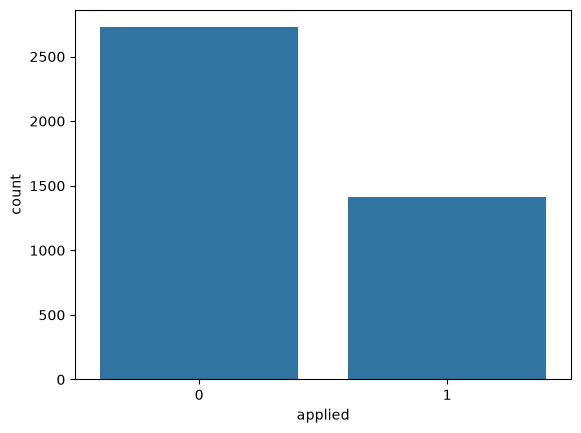

In [50]:
# Cada resume_id aparece em um único split e mantém suas 10 recomendações.
print(ground_truth.groupby("recommendation_engine").size())
print(ground_truth[["applied", "adherence_score"]].describe())
print("#"*5,"Proporção dos dados","#"*5)
print(ground_truth['applied'].value_counts(normalize=True))
sns.countplot(x="applied",data=ground_truth)


adherence_score
3    0.284058
2    0.210870
5    0.204589
1    0.151691
4    0.148792
Name: proportion, dtype: float64


<Axes: xlabel='adherence_score', ylabel='count'>

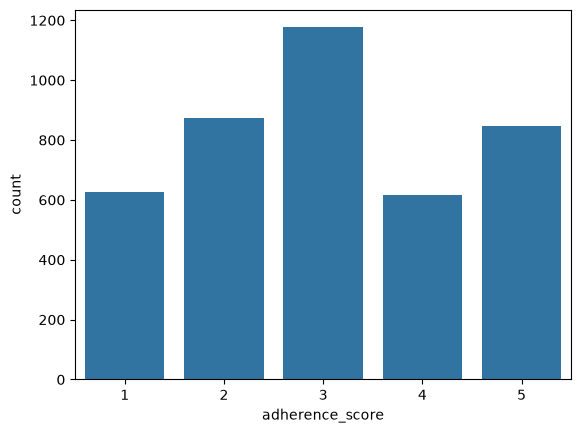

In [51]:
print(ground_truth['adherence_score'].value_counts(normalize=True))
sns.countplot(x="adherence_score",data=ground_truth)


### 4. Efetuando treinamento conjunto da RGCN e do decoder

O decoder recebe o vetor `[embedding_resume || embedding_opportunity]`. A MLP e a OrdinalMLP compartilham essa entrada, mas possuem parâmetros e saídas independentes. A loss total é a soma da `BCEWithLogitsLoss` da previsão binária com uma `coral_loss`. Como o `coral-pytorch` usa rótulos ordinais iniciando em zero, os valores `1..5` são convertidos para `0..4` somente na construção dos `levels`; as previsões são convertidas de volta para `1..5`.

#### Coral? O que é?

Coral é uma função de ativação para a camada de saída que lida com previsões ordinais, como a escala Likert de 1 a 5. Diferentemente de `Softmax` que trata cada classe como independente, e que errar uma classificação prevendo 4 enquanto o valor real era 5, tem o mesmo impacto de prever 1 sendo que o real era 5, a Coral considera que o impacto é maior no erro de 1 para 5.

O CORAL (Consistent Rank Logits) é uma abordagem de classificação ordinal que adapta uma rede neural para prever classes ordenadas, como as notas de 1 a 5 do seu TCC, mantendo maior consistência entre as previsões dos diferentes níveis.

A ideia central é aprender os limites entre as classes sem tratar cada nota como uma categoria completamente independente.

## 1. Como o CORAL funciona?

Para prever uma nota de 1 a 5, o CORAL transforma o problema em quatro decisões cumulativas:

- $(Y>1$)
- $(Y>2$)
- $(Y>3$)
- $(Y>4$)

A diferença em relação a quatro classificadores independentes é que o CORAL utiliza pesos compartilhados entre os limites ordinais, enquanto cada limite possui seu próprio viés.

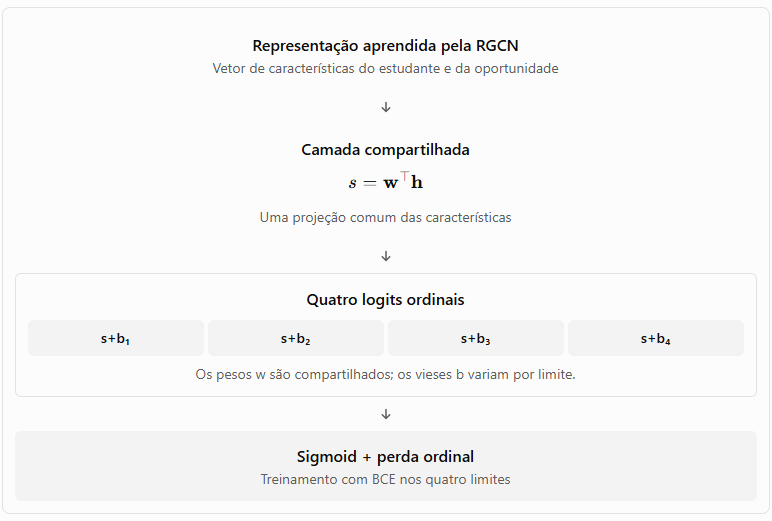

Matematicamente, o logit para cada limite $(k)$ (se o valor for maior que $k$, a condição $Y>X$ é verdadeira) é:

$[ z_k=\mathbf{w}^{\top}\mathbf{h}+b_k $]

Em seguida, a probabilidade cumulativa é:

$[ P(Y>k)=\sigma(z_k) $]

Sendo $\sigma$ a função sigmoide, que retorna um valor entre 0 e 1, como uma probabilidade

Como os pesos são compartilhados, o modelo aprende uma representação comum para todas as decisões. A estrutura dos vieses permite diferenciar os limites.

## 2. Como o treinamento acontece?

Suponha que a nota real de uma avaliação seja 4. O modelo recebe quatro alvos:

| Limite    | Alvo | Significado              |
| --------- | ---- | ------------------------ |
| $(Y>1$) | 1    | A nota é maior que 1     |
| $(Y>2$) | 1    | A nota é maior que 2     |
| $(Y>3$) | 1    | A nota é maior que 3     |
| $(Y>4$) | 0    | A nota não é maior que 4 |

O CORAL calcula a Binary Cross-Entropy para cada limite e combina as perdas:

$[ L=-\frac{1}{4}\sum\_{k=1}^{4} \left[y_k\log(p_k)+(1-y_k)\log(1-p_k)\right] $]

Durante o treinamento, o backpropagation ajusta os pesos compartilhados e os vieses para melhorar as quatro previsões.

A vantagem é que as decisões não são aprendidas por quatro classificadores completamente independentes: todas utilizam a mesma projeção das características de entrada.

## 3. Como converter as previsões em uma nota?

Suponha que o modelo produza as seguintes probabilidades cumulativas:

| Previsão     | Probabilidade |
| ------------ | ------------- |
| $(P(Y>1)$) | 0,95          |
| $(P(Y>2)$) | 0,85          |
| $(P(Y>3)$) | 0,70          |
| $(P(Y>4)$) | 0,20          |

Com limiar de 0,5, três limites são positivos. Portanto, a nota prevista é:

$[ \hat{Y}=1+\sum\_{k=1}^{4}\mathbb{1}[p_k\geq0{,}5]=4 $]

In [52]:
from coral_pytorch.dataset import levels_from_labelbatch, proba_to_label
from coral_pytorch.layers import CoralLayer
from coral_pytorch.losses import coral_loss

NUM_CLASSES = 5

class MLP(torch.nn.Module):
    def __init__(self, in_features, out_features, num_hidden_1=300, num_hidden_2=300):
        super().__init__()
        self.network = torch.nn.Sequential(
            torch.nn.Linear(in_features, num_hidden_1, bias=False), #Camada padrão: agrega os valores da camada anterior com peso, só que sem o bias (y = ax)
            torch.nn.LeakyReLU(), #A ReLU costuma zerar valores negativos. Essa aplica um peso alpha (valor padrão=0.01) sobre os valores negativos, reduzindo o risco de neurônios que deixam de aprender por receberem exclusivamente ativações negativas.
            torch.nn.Dropout(0.2), #Desativa 20% dos neurônios durante o treinamento, reduzindo risco de overfitting
            torch.nn.BatchNorm1d(num_hidden_1), # Aplica normalização estilo Z-Score, usando média e desvio padrão do lote, buscando estabilizar as distribuições das ativações, podendo melhorar a estabilidade e a velocidade de convergência do treinamento
            torch.nn.Linear(num_hidden_1, num_hidden_2, bias=False),
            torch.nn.LeakyReLU(),
            torch.nn.Dropout(0.2),
            torch.nn.BatchNorm1d(num_hidden_2),
        )
        self.output = torch.nn.Linear(num_hidden_2, out_features)

    def forward(self, x):
        return self.output(self.network(x))

class OrdinalMLP(torch.nn.Module):
    def __init__(self, in_features, num_classes=NUM_CLASSES):
        super().__init__()
        self.network = torch.nn.Sequential(
            torch.nn.Linear(in_features, 300, bias=False), 
            torch.nn.LeakyReLU(), 
            torch.nn.Dropout(0.2), 
            torch.nn.BatchNorm1d(300),
            torch.nn.Linear(300, 300, bias=False),
            torch.nn.LeakyReLU(),
            torch.nn.Dropout(0.2),
            torch.nn.BatchNorm1d(300),
        )
        # CoralLayer produz num_classes - 1 logits para as fronteiras ordinais.
        self.output = CoralLayer(size_in=300, num_classes=num_classes)

    def forward(self, x):
        logits = self.output(self.network(x))
        return logits, torch.sigmoid(logits)

class Decoder(torch.nn.Module):
    def __init__(self, embedding_dim):
        super().__init__()
        pair_dim = 2 * embedding_dim
        self.applied_mlp = MLP(pair_dim, out_features=1)
        self.adherence_mlp = OrdinalMLP(pair_dim)

    def forward(self, z_resume, z_opportunity):
        pair_embeddings = torch.cat([z_resume, z_opportunity], dim=-1)
        applied_logits = self.applied_mlp(pair_embeddings).squeeze(-1)
        adherence_logits, adherence_probas = self.adherence_mlp(pair_embeddings)
        return {
            "applied_logits": applied_logits,
            "applied_probas": torch.sigmoid(applied_logits),
            "adherence_logits": adherence_logits,
            "adherence_probas": adherence_probas,
        }

decoder = Decoder(embedding_dim=embeddings_dimension).to(device)
optimizer = torch.optim.Adam(
    list(model.parameters()) + list(decoder.parameters()),
    lr=0.01,
    weight_decay=5e-4,
)

def multitask_loss(outputs, targets):
    applied_loss = F.binary_cross_entropy_with_logits(
        outputs["applied_logits"], targets["applied"]
    )
    # Os rótulos do CSV são 1..5; o CORAL recebe classes 0..4.
    adherence_levels = levels_from_labelbatch(
        targets["adherence"] - 1, num_classes=NUM_CLASSES
    ).to(device)
    adherence_loss = coral_loss(outputs["adherence_logits"], adherence_levels)
    total_loss = applied_loss + adherence_loss
    return total_loss, {
        "applied": applied_loss,
        "adherence": adherence_loss,
    }

def run_split(split):
    z = model(data.x, data.edge_index, data.edge_type)
    outputs = decoder(z[split["resume"]], z[split["opportunity"]])
    return multitask_loss(outputs, split)

num_epochs = 20 # Mais que isso gera overfitting e ele só faz previsões em 0 para applied e 3 para
train_losses = []
val_losses = []

for epoch in range(num_epochs):
    model.train()
    decoder.train()
    optimizer.zero_grad()
    loss, train_components = run_split(train_split)
    loss.backward()
    optimizer.step()

    model.eval()
    decoder.eval()
    with torch.no_grad():
        val_loss, val_components = run_split(val_split)

    train_losses.append(loss.item())
    val_losses.append(val_loss.item())
    print(
        f"Epoch {epoch + 1:03d} | "
        f"Train Loss: {loss.item():.4f} | "
        f"Val Loss: {val_loss.item():.4f}"
    )


Epoch 001 | Train Loss: 3.5731 | Val Loss: 6.1783
Epoch 002 | Train Loss: 3.7276 | Val Loss: 207.0488
Epoch 003 | Train Loss: 5.8450 | Val Loss: 63.2440
Epoch 004 | Train Loss: 3.9340 | Val Loss: 22.2028
Epoch 005 | Train Loss: 3.5093 | Val Loss: 10.1291
Epoch 006 | Train Loss: 3.3708 | Val Loss: 8.7071
Epoch 007 | Train Loss: 3.4664 | Val Loss: 4.5862
Epoch 008 | Train Loss: 3.4044 | Val Loss: 5.8386
Epoch 009 | Train Loss: 3.4080 | Val Loss: 7.7384
Epoch 010 | Train Loss: 3.4625 | Val Loss: 4.7224
Epoch 011 | Train Loss: 3.4589 | Val Loss: 3.6049
Epoch 012 | Train Loss: 3.3662 | Val Loss: 5.5270
Epoch 013 | Train Loss: 3.3552 | Val Loss: 5.0705
Epoch 014 | Train Loss: 3.3144 | Val Loss: 3.5701
Epoch 015 | Train Loss: 3.2588 | Val Loss: 3.1819
Epoch 016 | Train Loss: 3.2134 | Val Loss: 3.7013
Epoch 017 | Train Loss: 3.2023 | Val Loss: 3.6818
Epoch 018 | Train Loss: 3.1612 | Val Loss: 3.3350
Epoch 019 | Train Loss: 3.1325 | Val Loss: 3.2070
Epoch 020 | Train Loss: 3.1225 | Val Loss: 3.

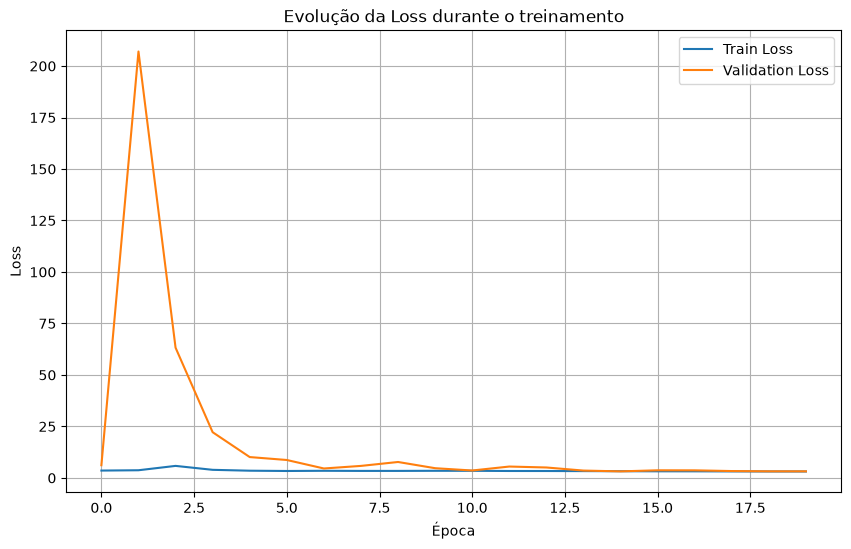

In [53]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.plot(
    train_losses,
    label="Train Loss"
)

plt.plot(
    val_losses,
    label="Validation Loss"
)

plt.xlabel("Época")
plt.ylabel("Loss")

plt.title("Evolução da Loss durante o treinamento")

plt.legend()
plt.grid(True)

plt.show()


### 5. Avaliação final do modelo

In [54]:
model.eval()
decoder.eval()
with torch.no_grad():
    z = model(data.x, data.edge_index, data.edge_type)
    test_outputs = decoder(
        z[test_split["resume"]],
        z[test_split["opportunity"]],
    )
    test_loss, test_components = multitask_loss(test_outputs, test_split)

    applied_predictions = (test_outputs["applied_probas"] >= 0.5).long()
    adherence_predictions = proba_to_label(test_outputs["adherence_probas"]) + 1

print(f"Perda final MLP (candidatura): {test_components['applied'].item():.4f}")
print(f"Perda final Ordinal MLP (aderência): {test_components['adherence'].item():.4f}")
print(f"Perda final total: {test_loss.item():.4f}")

# Preparação dos rótulos e das probabilidades para as duas saídas.
y_applied_true = test_split["applied"].long().detach().cpu().numpy()
y_applied_pred = applied_predictions.detach().cpu().numpy()
y_applied_score = test_outputs["applied_probas"].detach().cpu().numpy()

# O CORAL retorna P(y > k) para k=0..3. Essas probabilidades
# são convertidas em probabilidades das classes 1..5.
adherence_cumulative_probas = test_outputs["adherence_probas"]
adherence_class_probas = torch.cat(
    [
        1 - adherence_cumulative_probas[:, :1],
        adherence_cumulative_probas[:, :-1] - adherence_cumulative_probas[:, 1:],
        adherence_cumulative_probas[:, -1:],
    ],
    dim=1,
)
adherence_class_probas = adherence_class_probas.clamp_min(0)
adherence_class_probas = adherence_class_probas / adherence_class_probas.sum(
    dim=1, keepdim=True
).clamp_min(1e-12)

y_adherence_true = (test_split["adherence"] - 1).detach().cpu().numpy()
y_adherence_pred = (adherence_predictions - 1).detach().cpu().numpy()
y_adherence_score = adherence_class_probas.detach().cpu().numpy()
adherence_labels = np.arange(NUM_CLASSES)

def macro_ovr_roc_auc(y_true, class_scores, class_labels):
    aucs = []
    for class_index, class_label in enumerate(class_labels):
        binary_true = (y_true == class_label).astype(np.int64)
        if np.unique(binary_true).size == 2:
            aucs.append(roc_auc_score(binary_true, class_scores[:, class_index]))
    return float(np.mean(aucs)) if aucs else float("nan")

applied_confusion = confusion_matrix(
    y_applied_true, y_applied_pred, labels=[0, 1]
)
adherence_confusion = confusion_matrix(
    y_adherence_true, y_adherence_pred, labels=adherence_labels
)

print("Matriz de confusão — applied:")
display(
    pd.DataFrame(
        applied_confusion,
        index=["Real 0", "Real 1"],
        columns=["Predito 0", "Predito 1"],
    )
)
print("Matriz de confusão — adherence_score:")
display(
    pd.DataFrame(
        adherence_confusion,
        index=[f"Real {label + 1}" for label in adherence_labels],
        columns=[f"Predito {label + 1}" for label in adherence_labels],
    )
)

print("#"*5,"Métricas — applied:","#"*5)
print(f"Acurácia: {accuracy_score(y_applied_true, y_applied_pred):.4f}")
print(f"Precisão: {precision_score(y_applied_true, y_applied_pred, zero_division=0):.4f}")
print(f"Recall: {recall_score(y_applied_true, y_applied_pred, zero_division=0):.4f}")
print(f"F1-score: {f1_score(y_applied_true, y_applied_pred, zero_division=0):.4f}")
applied_roc_auc = roc_auc_score(y_applied_true, y_applied_score)
if np.unique(y_applied_true).size == 2:
    print(f"Área sob a curva ROC (AUC): {applied_roc_auc:.4f}")
    auc_explanation = (
        "Palpite Aleatório" if applied_roc_auc < 0.7 else
        "Bom desempenho" if applied_roc_auc >= 0.7 and applied_roc_auc < 0.9
        else "Excelente"
    )
    print(f"Interpretação dessa AUC: {auc_explanation}")
else:
    print("Área sob a curva ROC: indefinida; o teste de applied contém apenas uma classe real.")

print("\n","#"*5,"Métricas — adherence_score (média macro):","#"*5)
print(f"Acurácia: {accuracy_score(y_adherence_true, y_adherence_pred):.4f}")
print(f"Precisão Média (Calcula a precisão por classe, soma e retorna a média): {precision_score(y_adherence_true, y_adherence_pred, labels=adherence_labels, average='macro', zero_division=0):.4f}")
print(f"Recall Médio (Calcula o recall por classe, soma e retorna a média): {recall_score(y_adherence_true, y_adherence_pred, labels=adherence_labels, average='macro', zero_division=0):.4f}")
print(f"F1-score Médio (Calcula o F1-Score por classe, soma e retorna a média): {f1_score(y_adherence_true, y_adherence_pred, labels=adherence_labels, average='macro', zero_division=0):.4f}")
adherence_roc_auc = macro_ovr_roc_auc(
    y_adherence_true, y_adherence_score, adherence_labels
)
if np.isnan(adherence_roc_auc):
    print("Área sob a curva ROC: indefinida; nenhuma classe de adherence_score possui exemplos positivos e negativos.")
else:
    print(f"Área sob a curva ROC (AUC): {adherence_roc_auc:.4f}")
    auc_explanation = (
        "Palpite Aleatório" if adherence_roc_auc < 0.7 else
        "Bom desempenho" if adherence_roc_auc >= 0.7 and adherence_roc_auc < 0.9
        else "Excelente"
    )

    print(f"Interpretação dessa AUC: {auc_explanation}")

# ------------------------------------------------------------
# Exportação das previsões do conjunto de teste
# ------------------------------------------------------------
# O dataframe de saída usa os UUIDs originais, não os índices PyTorch/GDS.
idx_to_resume_id = {
    node_id_to_idx[int(row.gds_node_id)]: row.resume_id
    for row in resume_nodes.itertuples()
    if int(row.gds_node_id) in node_id_to_idx
}
idx_to_opportunity_id = {
    node_id_to_idx[int(row.gds_node_id)]: row.opportunity_id
    for row in opportunity_nodes.itertuples()
    if int(row.gds_node_id) in node_id_to_idx
}

test_resume_indices = test_split["resume"].detach().cpu().tolist()
test_opportunity_indices = test_split["opportunity"].detach().cpu().tolist()

rgcn_prevs = pd.DataFrame({
    "resume_id": [idx_to_resume_id[idx] for idx in test_resume_indices],
    "opportunity_id": [idx_to_opportunity_id[idx] for idx in test_opportunity_indices],
    "recommendation_engine": "gnn",
    "applied": applied_predictions.detach().cpu().numpy().astype(np.int64),
    "adherence_score": adherence_predictions.detach().cpu().numpy().astype(np.int64),
})

prediction_path = Path("playground/rgcn_prevs.csv")
if not prediction_path.parent.exists():
    prediction_path = Path("rgcn_prevs.csv")

rgcn_prevs.to_csv(prediction_path, index=False)
print(f"Previsões exportadas para: {prediction_path.resolve()}")
display(rgcn_prevs.head())

Perda final MLP (candidatura): 0.6553
Perda final Ordinal MLP (aderência): 2.5326
Perda final total: 3.1878
Matriz de confusão — applied:


,Predito 0,Predito 1
Real 0,501,57
Real 1,244,28


Matriz de confusão — adherence_score:


,Predito 1,Predito 2,Predito 3,Predito 4,Predito 5
Real 1,8,61,61,4,0
Real 2,17,86,67,6,2
Real 3,16,103,95,5,8
Real 4,12,50,57,3,0
Real 5,12,83,66,8,0


##### Métricas — applied: #####
Acurácia: 0.6373
Precisão: 0.3294
Recall: 0.1029
F1-score: 0.1569
Área sob a curva ROC (AUC): 0.5209
Interpretação dessa AUC: Palpite Aleatório

 ##### Métricas — adherence_score (média macro): #####
Acurácia: 0.2313
Precisão Média (Calcula a precisão por classe, soma e retorna a média): 0.1475
Recall Médio (Calcula o recall por classe, soma e retorna a média): 0.1972
F1-score Médio (Calcula o F1-Score por classe, soma e retorna a média): 0.1518
Área sob a curva ROC (AUC): 0.5001
Interpretação dessa AUC: Palpite Aleatório
Previsões exportadas para: /home/lsarai/tcc-gnn-synth-data/rgcn_prevs.csv


,resume_id,opportunity_id,recommendation_engine,applied,adherence_score
0,00a4638f-5c28-4c67-8c0a-9a58b5f46d92,5891e630-af03-4504-923c-b84142993738,gnn,0,3
1,00a4638f-5c28-4c67-8c0a-9a58b5f46d92,5527015a-7861-4d48-9098-5b681ff2b443,gnn,0,3
2,00a4638f-5c28-4c67-8c0a-9a58b5f46d92,bbe46f3e-0eb7-4cbf-9932-ee2511a07e91,gnn,0,3
3,00a4638f-5c28-4c67-8c0a-9a58b5f46d92,8d1bd2cb-15f3-4cf8-9792-8f9f51533bda,gnn,0,3
4,00a4638f-5c28-4c67-8c0a-9a58b5f46d92,c7152838-bf68-4d3c-ab79-8c0ab46845ef,gnn,0,3


## Treinando RGAT para gerar embeddings

### 1. Definindo arquitetura da rede

Para testar, vamos supor uma RGAT no formato:
```txt

                 X
          [2524 × 768]
              │
              ▼
       ┌──────────────┐
       │   RGATConv   │
       │ 768 → 768    │
       └──────────────┘
              │
            ReLU
              │
              ▼
       ┌──────────────┐
       │   RGATConv   │
       │ 768 → 768     │
       └──────────────┘
              │
              ▼
          Z(matriz X após GNN) [2524 × 768]
```

In [55]:
# Define the RGAT architecture
class RGAT(torch.nn.Module):
    def __init__(
            self,
            input_dim,
            hidden_dim,
            output_dim,
            num_relations
        ):
        super().__init__()
        self.conv1 = RGATConv(
            in_channels=input_dim,
            out_channels=hidden_dim,
            num_relations=num_relations,
            concat=False,
            heads=1)
        self.conv2 = RGATConv(
            in_channels=hidden_dim,
            out_channels=output_dim,
            num_relations=num_relations,
            concat=False,
            heads=1)

    def forward(self, data):
        x, edge_index,edge_type = data.x, data.edge_index, data.edge_type

        x = self.conv1(x, edge_index,edge_type)
        x = F.relu(x)
        # x = F.dropout(x, training=self.training)
        x = self.conv2(x, edge_index,edge_type)

        #Retorna a matriz de features agregada
        return x

In [56]:
# criando modelo e carregando na CPU ou GPU
model_rgat = RGAT(
    input_dim=embeddings_dimension,
    hidden_dim=embeddings_dimension,
    output_dim=embeddings_dimension,
    num_relations=len(relations)
    ).to(device)

# Inspecionando arquitetura
print(summary(model_rgat))

# Carregando os dados de entrada na CPU ou GPU
data = data.to(device)

# O RGAT, quando executado, usa o mesmo decoder multitarefa.
decoder_rgat = Decoder(embedding_dim=embeddings_dimension).to(device)
optimizer_rgat = torch.optim.Adam(
    list(model_rgat.parameters()) + list(decoder_rgat.parameters()),
    lr=0.01,
    weight_decay=5e-4,
)

Layer (type:depth-idx)                   Param #
RGAT                                     --
├─RGATConv: 1-1                          4,134,144
│    └─SumAggregation: 2-1               --
│    └─ReLU: 2-2                         --
├─RGATConv: 1-2                          4,134,144
│    └─SumAggregation: 2-3               --
│    └─ReLU: 2-4                         --
Total params: 8,268,288
Trainable params: 8,268,288
Non-trainable params: 0


### 2. Treinando RGAT
Como os conjuntos de treinamento, validação e teste já foram gerados para o modelo anterior, vamos reaproveitá-los

In [57]:
# num_epochs = 100

# train_losses_rgat = []
# val_losses_rgat = []

# for epoch in range(num_epochs):

#     model_rgat.train()
#     decoder_rgat.train()

#     optimizer_rgat.zero_grad()

#     # --------------------------------------------------------
#     # GNN
#     # --------------------------------------------------------

#     z = model_rgat(data)
#     train_outputs = decoder_rgat(
#         z[train_split["resume"]], z[train_split["opportunity"]]
#     )
#     loss, _ = multitask_loss(train_outputs, train_split)

#     # --------------------------------------------------------
#     # Backpropagation
#     # --------------------------------------------------------

#     loss.backward()

#     optimizer_rgat.step()


#     # ========================================================
#     # Validação
#     # ========================================================

#     model_rgat.eval()
#     decoder_rgat.eval()

#     with torch.no_grad():

#         z = model_rgat(data)

#         val_outputs = decoder_rgat(
#             z[val_split["resume"]], z[val_split["opportunity"]]
#         )
#         val_loss, _ = multitask_loss(val_outputs, val_split)

#         train_losses_rgat.append(loss.item())
#         val_losses_rgat.append(val_loss.item())
#     print(
#         f"Epoch {epoch + 1:03d} | "
#         f"Train Loss: {loss.item():.4f} | "
#         f"Val Loss: {val_loss.item():.4f}"
#     )

### RGAT consome muita memória

Na célula anterior, a RGAT tentou alocar 100GB de memória!

Para que RGAT possa ser executada, precisaria simplificar muito o tamanho dos embeddings gerados. E como estamos partindo de um embedding de 768 dimensões, poderia perder muita informação

## Retornando recomendações - RGCN

Vamos procurar o melhor match primeiro

In [58]:
# Decoder multitarefa usado para ordenar recomendações por probabilidade de aplicação.
def find_best_resume_match(z, decoder, resume_ids, opportunity_ids):
    decoder.eval()
    resume_tensor = torch.as_tensor(resume_ids, dtype=torch.long, device=z.device)
    opportunity_tensor = torch.as_tensor(opportunity_ids, dtype=torch.long, device=z.device)
    z_resumes = z[resume_tensor]
    z_opportunities = z[opportunity_tensor]
    num_resumes = len(resume_ids)
    num_opportunities = len(opportunity_ids)
    pair_resumes = z_resumes[:, None, :].expand(-1, num_opportunities, -1).reshape(-1, z.size(-1))
    pair_opportunities = z_opportunities[None, :, :].expand(num_resumes, -1, -1).reshape(-1, z.size(-1))

    with torch.no_grad():
        outputs = decoder(pair_resumes, pair_opportunities)
        applied = outputs["applied_probas"]
        adherence = proba_to_label(outputs["adherence_probas"]) + 1

    best_flat_index = torch.argmax(applied)
    best_flat = int(best_flat_index.item())
    best_resume_idx = best_flat // num_opportunities
    best_opportunity_idx = best_flat % num_opportunities
    return (
        resume_ids[best_resume_idx],
        opportunity_ids[best_opportunity_idx],
        {
            "applied_probability": applied[best_flat_index].item(),
            "adherence_score": int(adherence[best_flat_index].item()),
        },
    )

In [59]:
model.eval()
decoder.eval()
with torch.no_grad():
    z = model(data.x, data.edge_index, data.edge_type)

best_resume_pytorch_id, best_opportunity_pytorch_id, best_prediction = find_best_resume_match(
    z=z,
    decoder=decoder,
    resume_ids=resume_ids,
    opportunity_ids=opportunity_ids,
)

print("Melhor Resume PyTorch ID:", best_resume_pytorch_id)
print("Melhor Oportunidade PyTorch ID:", best_opportunity_pytorch_id)
print("Previsões:", best_prediction)

Melhor Resume PyTorch ID: 2900
Melhor Oportunidade PyTorch ID: 2672
Previsões: {'applied_probability': 1.0, 'adherence_score': 1}


In [60]:

resume_id = resume_ids[0]
z_resume = z[torch.tensor([resume_id], dtype=torch.long, device=z.device)]
z_opportunities = z[torch.tensor(opportunity_ids, dtype=torch.long, device=z.device)]

decoder.eval()
with torch.no_grad():
    outputs = decoder(
        z_resume.expand(len(opportunity_ids), -1),
        z_opportunities,
    )
    applied_probabilities = outputs["applied_probas"]
    adherence_predictions = proba_to_label(outputs["adherence_probas"]) + 1

k = min(10, len(opportunity_ids))
top_scores, top_indices = torch.topk(applied_probabilities, k=k)
top_opportunity_ids = torch.tensor(opportunity_ids, device=z.device)[top_indices]

top_10 = [
    {
        "opportunity_pytorch_id": int(opportunity_id),
        "applied_probability": float(score),
        "applied": bool(score >= 0.5),
        "adherence_score": int(adherence_predictions[index]),
    }
    for index, opportunity_id, score
    in zip(top_indices, top_opportunity_ids, top_scores)
]

top_10

[{'opportunity_pytorch_id': 2672,
  'applied_probability': 0.9948790073394775,
  'applied': True,
  'adherence_score': 1},
 {'opportunity_pytorch_id': 2666,
  'applied_probability': 0.9793789386749268,
  'applied': True,
  'adherence_score': 1},
 {'opportunity_pytorch_id': 3393,
  'applied_probability': 0.7923736572265625,
  'applied': True,
  'adherence_score': 2},
 {'opportunity_pytorch_id': 2066,
  'applied_probability': 0.6280603408813477,
  'applied': True,
  'adherence_score': 2},
 {'opportunity_pytorch_id': 2187,
  'applied_probability': 0.6147885322570801,
  'applied': True,
  'adherence_score': 3},
 {'opportunity_pytorch_id': 1959,
  'applied_probability': 0.5991999506950378,
  'applied': True,
  'adherence_score': 3},
 {'opportunity_pytorch_id': 3635,
  'applied_probability': 0.5870522260665894,
  'applied': True,
  'adherence_score': 2},
 {'opportunity_pytorch_id': 2058,
  'applied_probability': 0.5773108005523682,
  'applied': True,
  'adherence_score': 3},
 {'opportunity_p

## Explicabilidade
Existem várias técnicas de explicabilidade que podemos aplicar para entender as previsões feitas pelo grafo:

![Diagrama Explicabilidade GNN](../knowledge/02%20-%20assets/diagrama-explicabilidade-gnn.png)

Para um primeiro teste, vamos tentar descobrir quais nós foram mais relevantes para a geração do embedding agregado com GNNExplainer

Nesse contexto, vamos explicar a melhor recomendação feita pelo decoder, usando o logit de `applied` como fenômeno-alvo. A explicação continua sendo da RGCN, mas agora a relevância é calculada para a saída supervisionada do decoder.

Para consulta no neo4j, a dupla é:
* `Resume`: id = "f5adb2fd-3819-4a48-852c-7c20420dde1a"; \<id\> ou GDSID = 1953
* `Opportunity`: id = "9c521a58-7784-4725-bdb0-b6865fa30abd"; \<id\> ou GDSID = 2128 

In [61]:
class RecommendationModel(torch.nn.Module):

    def __init__(self, rgcn, decoder):
        super().__init__()
        self.rgcn = rgcn
        self.decoder = decoder

    def forward(
        self,
        x,
        edge_index,
        edge_type,
        edge_label_index
    ):

        z = self.rgcn(
            x,
            edge_index,
            edge_type
        )

        z_resume = z[edge_label_index[0]]
        z_opportunity = z[edge_label_index[1]]

        return self.decoder(
            z_resume,
            z_opportunity,
        )["applied_logits"]

In [62]:
from torch_geometric.explain import GNNExplainer,Explainer

recommendation_model = RecommendationModel(model, decoder)

explainer = Explainer(
    model=recommendation_model, #RGCN com ajuste para explicabilidade
    algorithm=GNNExplainer(epochs=100),
    explanation_type="phenomenon", #Vamos avaliar um evento, não o modelo inteiro
    node_mask_type="object", #Gera uma pontuação de importância por nó. Se fosse "attributes", seria por features, ou seja, um valor pra cada uma das 768 features
    edge_mask_type=None,
    model_config=dict(
        mode="regression", #Estamos trabalhando com regressão
        task_level="edge", #Eh uma tarefa de edge-prediction
        return_type="raw" #O modelo retorna o logit cru da previsão de applied
    )
)

target_applied = torch.tensor(
    [float(best_prediction["applied_probability"] >= 0.5)],
    dtype=torch.float32,
    device=data.x.device,
)

target_edge_label_index = torch.tensor(
    [
        [best_resume_pytorch_id],
        [best_opportunity_pytorch_id]
    ],
    dtype=torch.long,
    device=data.x.device,
)

explanation = explainer(
    x=data.x,
    edge_index=data.edge_index,
    edge_type=data.edge_type,
    edge_label_index=target_edge_label_index,
    target=target_applied,
)

In [65]:
import pandas as pd

# ============================================================
# 1. Node mask -> importância por índice PyTorch
# ============================================================

node_importance = (
    explanation.node_mask
    .squeeze(-1)
    .detach()
    .cpu()
    .numpy()
)

# ============================================================
# 2. PyTorch ID -> GDS ID
#    all_node_ids deve estar na mesma ordem usada para criar x
# ============================================================

idx_to_gds_id = {
    idx: id
    for id,idx in node_id_to_idx.items()
}

importance_df = pd.DataFrame({
    "pyTorchID": range(len(node_importance)),
    "GDSID": [
        idx_to_gds_id[idx]
        for idx in range(len(node_importance))
    ],
    "relevance": node_importance
})

# ============================================================
# 3. Manter somente nós com importância > 0
# ============================================================

importance_df = importance_df[
    importance_df["relevance"] > 0
].copy()

# ============================================================
# 4. Recuperar name/type diretamente do Neo4j
#
# ATENÇÃO:
# Esta query pressupõe que `gds_id` é uma propriedade
# persistida no nó Neo4j que corresponde ao GDSID.
# ============================================================

important_gds_ids = (
    importance_df["GDSID"]
    .astype(int)
    .tolist()
)

query = """
MATCH (n)
WHERE id(n) IN $gds_ids
RETURN
    id(n) AS GDSID,
    labels(n) AS class,
    n.title AS title,
    n.knowledge_area as knowledge,
    n.name AS name,
    n.type AS type
"""

neo4j_metadata_df = gds.run_cypher(
    query,
    params={
        "gds_ids": important_gds_ids
    }
)

# ============================================================
# 5. Associar metadados ao resultado do GNNExplainer
# ============================================================

importance_df = importance_df.merge(
    neo4j_metadata_df,
    on="GDSID",
    how="left"
)

# ============================================================
# 6. Ordenar pela importância
# ============================================================

importance_df = importance_df.sort_values(
    by="relevance",
    ascending=False
).reset_index(drop=True)

# ============================================================
# 7. Resultado final
# ============================================================
z_resume = z[best_resume_pytorch_id].unsqueeze(0)
z_opportunity = z[best_opportunity_pytorch_id].unsqueeze(0)

decoder.eval()

with torch.no_grad():
    final_outputs = decoder(z_resume, z_opportunity)
    final_applied_probability = final_outputs["applied_probas"][0].item()
    final_adherence_score = int(proba_to_label(final_outputs["adherence_probas"])[0].item()) + 1

print("Currículo alvo:")
best_resume_gds_id = idx_to_gds_id[best_resume_pytorch_id]
display(importance_df[importance_df["GDSID"] == best_resume_gds_id])
print("Oportunidade alvo:")
best_opportunity_gds_id = idx_to_gds_id[best_opportunity_pytorch_id]
display(importance_df[importance_df["GDSID"] == best_opportunity_gds_id])
print(
    f"Applied: {final_applied_probability:.4f} ({final_applied_probability * 100:.2f}%) | "
    f"Adherence: {final_adherence_score}"
)

display(importance_df[[
    
    "pyTorchID",
    "GDSID",
    "class",
    "name",
    "type",
    "relevance"
    ]
][:10])


print("Contagem de valores por tipo:",importance_df["class"].value_counts(),sep="\n")

Received notification from DBMS server: {severity: WARNING} {code: Neo.ClientNotification.Statement.FeatureDeprecationWarning} {category: DEPRECATION} {title: This feature is deprecated and will be removed in future versions.} {description: The query used a deprecated function: `id`.} {position: line: 3, column: 7, offset: 17} for query: '\nMATCH (n)\nWHERE id(n) IN $gds_ids\nRETURN\n    id(n) AS GDSID,\n    labels(n) AS class,\n    n.title AS title,\n    n.knowledge_area as knowledge,\n    n.name AS name,\n    n.type AS type\n'
Received notification from DBMS server: {severity: WARNING} {code: Neo.ClientNotification.Statement.FeatureDeprecationWarning} {category: DEPRECATION} {title: This feature is deprecated and will be removed in future versions.} {description: The query used a deprecated function: `id`.} {position: line: 5, column: 5, offset: 46} for query: '\nMATCH (n)\nWHERE id(n) IN $gds_ids\nRETURN\n    id(n) AS GDSID,\n    labels(n) AS class,\n    n.title AS title,\n    n.kno

Currículo alvo:


,pyTorchID,GDSID,relevance,class,title,knowledge,name,type
1,2900,3201,0.699939,[Resume],NaN,Desenvolvimento de Software,NaN,NaN


Oportunidade alvo:


,pyTorchID,GDSID,relevance,class,title,knowledge,name,type
21,2672,2922,0.344416,[Opportunity],Engenheiro de Software (Graduação) – Infraestr...,NaN,NaN,NaN


Applied: 1.0000 (100.00%) | Adherence: 1


,pyTorchID,GDSID,class,name,type,relevance
0,1401,1401,[Skill],design e administração de bases de dados e de ...,knowledge,0.705351
1,2900,3201,[Resume],NaN,NaN,0.699939
2,845,845,[Skill],PostgreSQL,knowledge,0.695480
3,374,374,[Skill],MySQL,knowledge,0.691311
4,1474,1474,[Skill],serviços,knowledge,0.691152
5,853,853,[Skill],sistemas de gestão de bases de dados,knowledge,0.682439
6,1475,1475,[Skill],serviços sem definição precisa,unknown,0.682055
7,472,472,[Skill],utilizar programação de «script»,hard,0.674808
8,1019,1019,[Skill],Python (programação informática),knowledge,0.667914
9,1476,1476,[Skill],serviços sem definição precisa,unknown,0.647692


Contagem de valores por tipo:
class
[Skill]          138
[Resume]           1
[Opportunity]      1
Name: count, dtype: int64


In [ ]:
#Limpando o grafo
G.drop()